# Does a sepsis early-warning model fail women?

Early prediction of sepsis in ICU patients, with a sex-stratified evaluation.

**Data:** PhysioNet / Computing in Cardiology Challenge 2019, hourly ICU records from two US hospital systems (A and B).
Source: https://physionet.org/content/challenge-2019/1.0.0/ (CC BY 4.0).

**Target:** `SepsisLabel`. In this dataset the label switches to 1 six hours *before* clinical sepsis onset (Sepsis-3),
so predicting it at hour *t* means warning about sepsis up to 6 hours ahead.

**Question:** a model can look good overall and still warn women later or less often than men.
We train classical ML models and Keras models, then compare how well each one works for female and male patients,
and test some simple ways to close any gap.

Notebook outline:
1. Setup
2. Load the raw data
3. Exploratory analysis (including by sex)
4. Patient-level splits
5. Feature engineering (only past information)
6. Evaluation and logging helpers
7. Classical ML experiments (scikit-learn)
8. Deep learning experiments (Keras + tf.data)
9. Fairness fixes
10. Cross-hospital test (train on A, test on B)
11. Figures and experiment table
12. Save the best models

## 1. Setup

In [1]:
import os, glob, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from tensorboard.plugins.hparams import api as hp_api
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = os.environ.get("DATA_DIR", "data/raw")   # training_setA/ and training_setB/ (.psv files from PhysioNet)
CACHE = os.environ.get("CACHE", "data/processed/hourly.parquet")
LOG_DIR = "logs"                 # TensorBoard
FIG_DIR = "figures"
MODEL_DIR = "models"
for d in ["data/processed", LOG_DIR, FIG_DIR, MODEL_DIR, "results"]:
    os.makedirs(d, exist_ok=True)

# QUICK=True runs a small version (few patients, 1 epoch) to check the pipeline end to end
QUICK = os.environ.get("QUICK", "0") == "1"
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| QUICK =", QUICK)

TensorFlow 2.21.0 | Keras 3.15.1 | QUICK = False


## 2. Load the raw data
Each patient is one pipe-separated file with one row per ICU hour. We stack them into one table and cache it.

In [2]:
def load_raw(data_dir):
    frames = []
    for hosp in ["A", "B"]:
        files = sorted(glob.glob(os.path.join(data_dir, f"training_set{hosp}", "*.psv")))
        for f in files:
            d = pd.read_csv(f, sep="|")
            d.insert(0, "patient", os.path.basename(f)[:-4])
            d.insert(1, "hospital", hosp)
            frames.append(d)
    return pd.concat(frames, ignore_index=True)

if os.path.exists(CACHE):
    raw = pd.read_parquet(CACHE)
else:
    raw = load_raw(DATA_DIR)
    raw.to_parquet(CACHE, index=False)

if QUICK:
    keep = raw.patient.drop_duplicates().sample(3000, random_state=SEED)
    raw = raw[raw.patient.isin(keep)].reset_index(drop=True)

raw = raw.sort_values(["patient", "ICULOS"]).reset_index(drop=True)
print(f"{len(raw):,} hourly rows, {raw.patient.nunique():,} patients, {raw.shape[1]} columns")
raw.head()

1,552,210 hourly rows, 40,336 patients, 43 columns


,patient,hospital,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
0,p000001,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,1,0
1,p000001,A,97.0,95.0,NaN,98.0,75.33,NaN,19.0,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,2,0
2,p000001,A,89.0,99.0,NaN,122.0,86.00,NaN,22.0,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,3,0
3,p000001,A,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,4,0
4,p000001,A,103.0,88.5,NaN,122.0,91.33,NaN,24.5,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,5,0


## 3. Exploratory analysis
`Gender` is coded 0 = female, 1 = male in this dataset.

In [3]:
VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"]
LABS = ["BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN", "Alkalinephos", "Calcium",
        "Chloride", "Creatinine", "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
        "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets"]
CLIN = VITALS + LABS
SEX_NAME = {0: "female", 1: "male"}

pat = raw.groupby("patient").agg(hospital=("hospital", "first"), sex=("Gender", "first"),
                                 age=("Age", "first"), sepsis=("SepsisLabel", "max"),
                                 hours=("ICULOS", "size"))
pat["sex_name"] = pat.sex.map(SEX_NAME)

print("Patients by hospital and sex")
display(pd.crosstab(pat.hospital, pat.sex_name, margins=True))
print("Sepsis rate (patients) by hospital and sex")
display(pd.crosstab(pat.hospital, pat.sex_name, values=pat.sepsis, aggfunc="mean").round(4))
print("Number of septic patients by sex:", pat.groupby("sex_name").sepsis.sum().to_dict())
print(f"Positive hours: {raw.SepsisLabel.mean():.2%} of all rows")

Patients by hospital and sex


sex_name,female,male,All
hospital,,,
A,8502,11834,20336
B,9268,10732,20000
All,17770,22566,40336


Sepsis rate (patients) by hospital and sex


sex_name,female,male
hospital,,
A,0.0821,0.0923
B,0.0534,0.0603


Number of septic patients by sex: {'female': 1193, 'male': 1739}
Positive hours: 1.80% of all rows


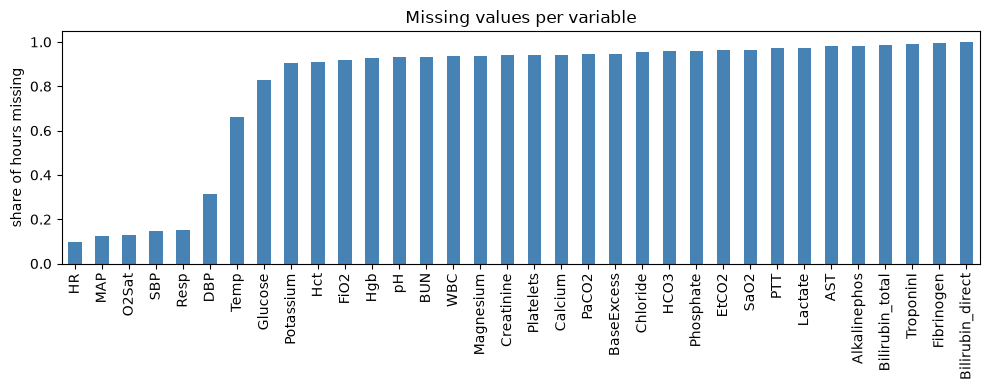

In [4]:
# How much is missing? Labs are mostly missing because they are only taken a few times a day.
miss = raw[CLIN].isna().mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 4))
miss.plot.bar(ax=ax, color="steelblue")
ax.set_ylabel("share of hours missing"); ax.set_title("Missing values per variable")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/missingness.png", dpi=150); plt.show()

,female,male,female/male
Lactate,0.024,0.029,0.831
WBC,0.062,0.065,0.956
Temp,0.319,0.353,0.904
HR,0.898,0.904,0.993
Creatinine,0.061,0.061,0.988
Platelets,0.058,0.061,0.957
pH,0.061,0.076,0.799


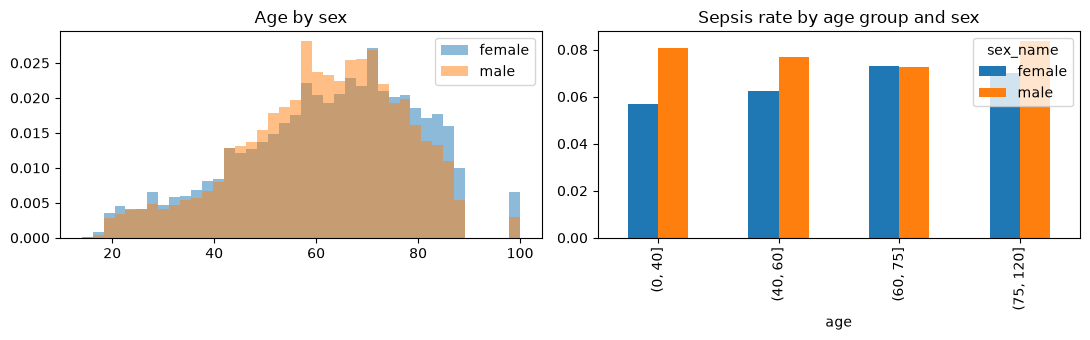

In [5]:
# Are women and men measured equally often? (more tests can mean more clinical suspicion)
meas = raw.groupby("Gender")[CLIN].apply(lambda d: d.notna().mean()).T
meas.columns = [SEX_NAME[c] for c in meas.columns]
meas["female/male"] = meas["female"] / meas["male"]
display(meas.loc[["Lactate", "WBC", "Temp", "HR", "Creatinine", "Platelets", "pH"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for s, g in pat.groupby("sex_name"):
    axes[0].hist(g.age, bins=40, alpha=.5, density=True, label=s)
axes[0].set_title("Age by sex"); axes[0].legend()
pd.crosstab(pd.cut(pat.age, [0, 40, 60, 75, 120]), pat.sex_name, values=pat.sepsis, aggfunc="mean").plot.bar(ax=axes[1])
axes[1].set_title("Sepsis rate by age group and sex"); axes[1].set_xlabel("age")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_sex_age.png", dpi=150); plt.show()

## 4. Patient-level splits
All hours of one patient go to the same split. A random row split would put hour 10 of a patient in training
and hour 11 in testing, which leaks information and inflates the scores.

* **Main split:** 70% train, 15% validation, 15% test, stratified by hospital, sex and sepsis.
* **Cross-hospital split:** train on hospital A, test on hospital B (section 10).

In [6]:
strata = pat.hospital + "_" + pat.sex.astype(str) + "_" + pat.sepsis.astype(str)
ids = pat.index.to_numpy(dtype=object)
tr_p, tmp_p = train_test_split(ids, test_size=0.30, stratify=strata.to_numpy(dtype=object), random_state=SEED)
va_p, te_p = train_test_split(tmp_p, test_size=0.50, stratify=strata.loc[tmp_p].to_numpy(dtype=object), random_state=SEED)
split_of = pd.Series("train", index=pat.index)
split_of[va_p] = "val"; split_of[te_p] = "test"
pat["split"] = split_of
display(pat.groupby(["split", "sex_name"]).agg(patients=("sepsis", "size"), septic=("sepsis", "sum")))

patients  septic
split sex_name                  
test  female        2665     178
      male          3386     261
train female       12440     836
      male         15795    1217
val   female        2665     179
      male          3385     261

## 5. Feature engineering
Every feature at hour *t* uses only hours up to *t* (no peeking at the future):

* last known value of each vital sign and lab (forward fill inside the patient)
* how many times each variable has been measured so far (testing intensity)
* rolling 6-hour mean, min, max, standard deviation and 6-hour change for the vital signs
* demographics and ICU info: age, sex, unit, hours since hospital admission, hours in ICU

Remaining gaps are filled with the training median inside each scikit-learn pipeline.

In [7]:
def make_features(df):
    df = df.sort_values(["patient", "ICULOS"]).copy()
    g = df.groupby("patient", sort=False)
    out = {}
    filled = g[CLIN].ffill()
    for c in CLIN:
        out[c] = filled[c]
    counts = df[CLIN].notna().groupby(df.patient, sort=False).cumsum()
    for c in CLIN:
        out[c + "_n"] = counts[c]
    fv = filled[VITALS].groupby(df.patient, sort=False)
    for stat in ["mean", "min", "max", "std"]:
        r = fv.rolling(6, min_periods=1).agg(stat).reset_index(level=0, drop=True)
        for c in VITALS:
            out[f"{c}_{stat}6"] = r[c]
    d6 = fv.diff(6)
    for c in VITALS:
        out[c + "_d6"] = d6[c]
    feats = pd.DataFrame(out, index=df.index)
    feats["Age"] = df.Age
    feats["Gender"] = df.Gender
    feats["Unit"] = np.select([df.Unit1 == 1, df.Unit2 == 1], [1, 2], 0)   # 0 = unknown
    feats["HospAdmTime"] = df.HospAdmTime
    feats["ICULOS"] = df.ICULOS
    meta = df[["patient", "hospital", "Gender", "ICULOS", "SepsisLabel"]].copy()
    return feats.astype("float32"), meta

t0 = time.time()
X_all, meta = make_features(raw)
meta["split"] = meta.patient.map(pat.split)
FEATURES = list(X_all.columns)
print(f"{X_all.shape[1]} features built in {time.time() - t0:.0f}s")

idx = {s: np.where(meta.split.values == s)[0] for s in ["train", "val", "test"]}
X = {s: X_all.iloc[i] for s, i in idx.items()}
y = {s: meta.SepsisLabel.values[i] for s, i in idx.items()}
M = {s: meta.iloc[i].reset_index(drop=True) for s, i in idx.items()}
for s in idx:
    print(f"{s:5s}: {len(idx[s]):>9,} hours, positive share {y[s].mean():.3%}")

113 features built in 11s


train: 1,088,968 hours, positive share 1.792%
val  :   233,722 hours, positive share 1.796%
test :   229,520 hours, positive share 1.830%


## 6. Evaluation and logging helpers

**Metrics.** Only about 2% of hours are positive, so accuracy is useless (always saying "no sepsis" gives 98%).
We report ROC-AUC and PR-AUC (average precision), which is more honest under heavy imbalance [Saito & Rehmsmeier, 2015].

**Alert threshold.** A hospital has to turn scores into alerts, and too many false alarms make staff ignore them
(alarm fatigue). So the main threshold is an *alarm budget*: chosen on the *validation* set so that only 5% of
non-sepsis hours raise an alert. At that same threshold we compare women and men on:

* recall (sensitivity): the *equal opportunity* gap [Hardt et al., 2016]
* false alarm rate, and false alerts per day for patients who never became septic
* patient level: share of septic patients who got an alert in the 24 hours before onset, and how many hours of warning
  they got (alerts earlier than that are counted as false alarms, not warnings)

As a second view we also report recall by sex at a threshold that catches 80% of positive hours overall (`r80_` columns).

Every experiment is logged to TensorBoard (scalars and HParams) and to `results/experiments.csv`.

In [8]:
def onset_hour(m):
    # SepsisLabel turns 1 at (onset - 6h), so onset = first positive ICULOS + 6
    pos = m[m.SepsisLabel == 1].groupby("patient").ICULOS.min()
    return pos + 6

ALARM_BUDGET = 0.05   # share of non-sepsis hours allowed to raise an alert

def threshold_for_recall(y_true, score, target=0.80):
    pos = np.sort(score[y_true == 1])
    return float(pos[int(np.floor((1 - target) * len(pos)))])

def threshold_for_fpr(y_true, score, budget=ALARM_BUDGET):
    neg = np.sort(score[y_true == 0])
    return float(neg[min(int(np.ceil((1 - budget) * len(neg))), len(neg) - 1)])

WARN_WINDOW = 24

def warning_lead(d, on):
    # hours between the first alert inside [onset - WARN_WINDOW, onset] and onset; NaN = no warning
    x = d[d.alert & d.patient.isin(on.index)].copy()
    x["onset"] = x.patient.map(on)
    x = x[(x.ICULOS <= x.onset) & (x.ICULOS >= x.onset - WARN_WINDOW)]
    first = x.groupby("patient").ICULOS.min()
    return (on - first.reindex(on.index))

def group_metrics(y_true, score, thr, m):
    alert = score >= thr
    res = {"auroc": roc_auc_score(y_true, score), "auprc": average_precision_score(y_true, score),
           "recall": alert[y_true == 1].mean(), "false_alarm": alert[y_true == 0].mean(),
           "precision": y_true[alert].mean() if alert.any() else 0.0}
    # patient level warning: only alerts in the WARN_WINDOW hours before onset count as a warning
    # (an alert 3 days before onset is a false alarm, not an early warning)
    on = onset_hour(m)
    d = m.assign(alert=alert)
    lead = warning_lead(d, on)
    res["septic_warned"] = lead.notna().mean() if len(lead) else 0.0
    res["lead_hours_median"] = float(lead.median()) if lead.notna().any() else 0.0
    # false alerts per 24h among patients who never became septic
    nonsep = d[~d.patient.isin(on.index)]
    res["alerts_per_day_nonseptic"] = nonsep.alert.sum() / max(len(nonsep), 1) * 24
    return res

def evaluate(score_val, score_test, mval=None, mtest=None, yval=None, ytest=None, thr=None):
    mval = M["val"] if mval is None else mval
    mtest = M["test"] if mtest is None else mtest
    yval = y["val"] if yval is None else yval
    ytest = y["test"] if ytest is None else ytest
    if thr is None:
        thr = threshold_for_fpr(yval, score_val)
    out = {"threshold": thr, "val_auprc": average_precision_score(yval, score_val)}
    for name, mask in [("all", np.ones(len(ytest), bool)), ("female", mtest.Gender.values == 0),
                       ("male", mtest.Gender.values == 1)]:
        r = group_metrics(ytest[mask], score_test[mask], thr, mtest[mask])
        out.update({f"{k}_{name}": v for k, v in r.items()})
    out["recall_gap_m_minus_f"] = out["recall_male"] - out["recall_female"]
    out["auroc_gap_m_minus_f"] = out["auroc_male"] - out["auroc_female"]
    # second operating point: catch 80% of positive hours
    t80 = threshold_for_recall(yval, score_val, 0.80)
    a80 = score_test >= t80
    g = mtest.Gender.values
    out["r80_recall_female"] = a80[(ytest == 1) & (g == 0)].mean()
    out["r80_recall_male"] = a80[(ytest == 1) & (g == 1)].mean()
    out["r80_false_alarm_all"] = a80[ytest == 0].mean()
    return out

RESULTS, SCORES = [], {}
TABLE_KEYS = ["val_auprc", "auroc_all", "auprc_all", "auroc_female", "auroc_male", "recall_female", "recall_male",
              "recall_gap_m_minus_f", "false_alarm_female", "false_alarm_male",
              "alerts_per_day_nonseptic_female", "alerts_per_day_nonseptic_male",
              "septic_warned_female", "septic_warned_male", "lead_hours_median_female",
              "lead_hours_median_male", "r80_recall_female", "r80_recall_male", "r80_false_alarm_all"]

# ---- cache: every trained model and its scores are saved, so re-running the notebook
# only re-does the evaluation. Set RETRAIN=1 to train everything again.
RETRAIN = os.environ.get("RETRAIN", "0") == "1"
RUN_DIR = "data/processed/runs"; os.makedirs(RUN_DIR, exist_ok=True)
os.makedirs(f"{MODEL_DIR}/runs", exist_ok=True)

def cache_get(run_id):
    p = f"{RUN_DIR}/{run_id}.npz"
    if RETRAIN or not os.path.exists(p):
        return None
    z = np.load(p)
    return z["sv"], z["st"], json.load(open(f"{RUN_DIR}/{run_id}.json"))

def cache_put(run_id, sv, st, info):
    np.savez_compressed(f"{RUN_DIR}/{run_id}.npz", sv=sv, st=st)
    json.dump(info, open(f"{RUN_DIR}/{run_id}.json", "w"))

def log_run(run_id, model_name, hparams, metrics, split="main (patient 70/15/15)", note=""):
    # TensorBoard: HParams + one scalar per metric, so the table can be checked against the logs
    with tf.summary.create_file_writer(os.path.join(LOG_DIR, "hparams", run_id)).as_default():
        hp_api.hparams({k: (v if isinstance(v, (int, float, str, bool)) else str(v)) for k, v in hparams.items()},
                       trial_id=run_id)
        for k, v in metrics.items():
            tf.summary.scalar(k, float(v), step=1)
    row = {"run": run_id, "model": model_name, "split": split,
           "hparams": json.dumps(hparams), **{k: metrics.get(k) for k in TABLE_KEYS}, "note": note}
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv("results/experiments.csv", index=False)
    print(f"{run_id}: AUROC {metrics['auroc_all']:.3f} | AUPRC {metrics['auprc_all']:.3f} | "
          f"val PR-AUC {metrics['val_auprc']:.3f} | recall F {metrics['recall_female']:.3f} vs M {metrics['recall_male']:.3f} | "
          f"warned F {metrics['septic_warned_female']:.2%} vs M {metrics['septic_warned_male']:.2%}")

## 7. Classical ML experiments (scikit-learn)

* **E1 Logistic regression:** linear baseline, class weights balanced.
* **E2 Random forest:** non-linear, trained on all positive hours plus a 25% sample of negative hours to keep it fast.
* **E3 Histogram gradient boosting:** strong default for tabular data [Grinsztajn et al., 2022].
* **E4 Gradient boosting, tuned:** smaller learning rate, more and bigger trees, L2 penalty.
* **E5 Gradient boosting without the sex feature:** does hiding sex from the model ("fairness through unawareness") change the gap?

In [9]:
def downsample_neg(Xd, yd, frac, seed=SEED):
    rng = np.random.default_rng(seed)
    keep = (yd == 1) | (rng.random(len(yd)) < frac)
    return Xd[keep], yd[keep]

def run_sklearn(run_id, name, model, hparams, cols=FEATURES, neg_frac=1.0, sample_weight=None, note=""):
    cols = [c for c in cols if X["train"][c].notna().any()]   # drop columns never measured in training
    cached = cache_get(run_id)
    if cached:
        sv, st, info = cached
        model = joblib.load(f"{MODEL_DIR}/runs/{run_id}.joblib")
    else:
        t0 = time.time()
        Xtr, ytr = X["train"][cols], y["train"]
        fit_kw = {}
        if neg_frac < 1:
            Xtr, ytr = downsample_neg(Xtr, ytr, neg_frac)
        if sample_weight is not None:
            fit_kw[model.steps[-1][0] + "__sample_weight"] = sample_weight
        model.fit(Xtr, ytr, **fit_kw)
        info = {"fit_seconds": round(time.time() - t0)}
        sv = model.predict_proba(X["val"][cols])[:, 1]
        st = model.predict_proba(X["test"][cols])[:, 1]
        model.used_cols = cols
        joblib.dump(model, f"{MODEL_DIR}/runs/{run_id}.joblib")
        cache_put(run_id, sv, st, info)
    SCORES[run_id] = (sv, st)
    log_run(run_id, name, {**hparams, **info}, evaluate(sv, st), note=note)
    return model

MODELS = {}
MODELS["E1"] = run_sklearn("E1_logreg", "LogisticRegression",
    make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  LogisticRegression(C=1.0, class_weight="balanced", max_iter=300)),
    {"C": 1.0, "class_weight": "balanced"}, note="linear baseline")

E1_logreg: AUROC 0.778 | AUPRC 0.084 | val PR-AUC 0.077 | recall F 0.280 vs M 0.294 | warned F 38.20% vs M 39.85%


In [10]:
MODELS["E2"] = run_sklearn("E2_random_forest", "RandomForest",
    make_pipeline(SimpleImputer(strategy="median"),
                  RandomForestClassifier(n_estimators=300 if not QUICK else 20, max_depth=14,
                                         min_samples_leaf=20, class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=SEED)),
    {"n_estimators": 300, "max_depth": 14, "min_samples_leaf": 20, "neg_sample": 0.25},
    neg_frac=0.25, note="negatives downsampled to 25%")

E2_random_forest: AUROC 0.834 | AUPRC 0.098 | val PR-AUC 0.094 | recall F 0.418 vs M 0.311 | warned F 57.87% vs M 43.68%


In [11]:
def hgb(lr=0.1, leaves=31, iters=300, l2=0.0):
    return make_pipeline(HistGradientBoostingClassifier(
        learning_rate=lr, max_leaf_nodes=leaves, max_iter=iters if not QUICK else 30, l2_regularization=l2,
        class_weight="balanced", early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
        random_state=SEED))

MODELS["E3"] = run_sklearn("E3_hgb_default", "HistGradientBoosting", hgb(),
                           {"learning_rate": 0.1, "max_leaf_nodes": 31, "max_iter": 300, "l2": 0.0})
MODELS["E4"] = run_sklearn("E4_hgb_tuned", "HistGradientBoosting", hgb(lr=0.05, leaves=63, iters=800, l2=1.0),
                           {"learning_rate": 0.05, "max_leaf_nodes": 63, "max_iter": 800, "l2": 1.0},
                           note="slower learning, bigger trees")
NO_SEX = [c for c in FEATURES if c != "Gender"]
NO_TIME = [c for c in FEATURES if c not in ("ICULOS", "HospAdmTime")]
MODELS["E5"] = run_sklearn("E5_hgb_no_sex", "HistGradientBoosting", hgb(lr=0.05, leaves=63, iters=800, l2=1.0),
                           {"learning_rate": 0.05, "max_leaf_nodes": 63, "max_iter": 800, "l2": 1.0,
                            "uses_sex": False}, cols=NO_SEX, note="sex feature removed")

E3_hgb_default: AUROC 0.831 | AUPRC 0.097 | val PR-AUC 0.094 | recall F 0.339 vs M 0.319 | warned F 57.30% vs M 55.56%


E4_hgb_tuned: AUROC 0.807 | AUPRC 0.082 | val PR-AUC 0.084 | recall F 0.285 vs M 0.282 | warned F 58.99% vs M 56.70%


E5_hgb_no_sex: AUROC 0.804 | AUPRC 0.081 | val PR-AUC 0.081 | recall F 0.275 vs M 0.277 | warned F 61.24% vs M 52.87%


**E14 Gradient boosting without the time features.** `ICULOS` (hours since ICU admission) turns out to be the strongest
feature. Part of that can be a dataset shortcut: septic patients' records are cut off a short time after onset, so
time in ICU partly reflects how the data was collected. E14 removes `ICULOS` and `HospAdmTime` to see how much the
model leans on them.

In [12]:
MODELS["E14"] = run_sklearn("E14_hgb_no_time", "HistGradientBoosting", hgb(),
                            {"learning_rate": 0.1, "max_leaf_nodes": 31, "max_iter": 300, "l2": 0.0, "uses_time": False},
                            cols=NO_TIME, note="ICULOS and HospAdmTime removed")

E14_hgb_no_time: AUROC 0.820 | AUPRC 0.095 | val PR-AUC 0.086 | recall F 0.316 vs M 0.312 | warned F 52.81% vs M 53.26%


## 8. Deep learning experiments (Keras + tf.data)

* **E6 MLP (Sequential API):** a feed-forward network on the same hourly features as the tree models.
* **E7 GRU (Functional API):** a recurrent network that reads each patient's stay hour by hour and outputs a risk at every hour.
  It only looks backwards, so it never sees the future. Inputs: standardised last-known values, a "measured this hour" flag
  for every variable, and demographics.
* **E8 GRU, bigger with more dropout and a lower learning rate.**
* **E9 GRU without class weights:** shows what the imbalance does if we ignore it.

All Keras inputs go through `tf.data` pipelines. Positive hours get a higher loss weight (about the negative/positive ratio)
unless stated otherwise. Training uses early stopping on validation PR-AUC and logs to TensorBoard.

In [13]:
# ---------- E6: Sequential MLP on hourly features ----------
imp = SimpleImputer(strategy="median").fit(X["train"])
sc = StandardScaler().fit(imp.transform(X["train"]))
Z = {s: np.clip(sc.transform(imp.transform(X[s])), -6, 6).astype("float32") for s in X}
POS_W = float((y["train"] == 0).sum() / max((y["train"] == 1).sum(), 1))
EPOCHS = 1 if QUICK else 40
print("positive weight", round(POS_W, 1))

def tab_ds(Zs, ys, shuffle, pos_w=1.0):
    w = np.where(ys == 1, pos_w, 1.0).astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((Zs, ys.astype("float32"), w))
    if shuffle:
        ds = ds.shuffle(200_000, seed=SEED)
    return ds.batch(2048).prefetch(tf.data.AUTOTUNE)

def callbacks(run_id, monitor="val_auprc"):
    return [keras.callbacks.EarlyStopping(monitor=monitor, mode="max", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor=monitor, mode="max", factor=0.5, patience=2),
            keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, "fit", run_id), histogram_freq=1)]

# validation sets use weight 1 for every real hour, so val PR-AUC is honest; padding hours get weight 0
METRICS = [keras.metrics.AUC(name="auroc"), keras.metrics.AUC(curve="PR", name="auprc")]

def build_mlp(n_in, units=(256, 128, 64), dropout=0.3, lr=1e-3):
    model = keras.Sequential([keras.Input((n_in,))] + sum(
        [[keras.layers.Dense(u), keras.layers.BatchNormalization(), keras.layers.ReLU(), keras.layers.Dropout(dropout)]
         for u in units], []) + [keras.layers.Dense(1, activation="sigmoid")], name="mlp")
    model.compile(keras.optimizers.Adam(lr), loss="binary_crossentropy", weighted_metrics=METRICS)
    return model

HIST = {}   # training history (loss and metrics per epoch) of every Keras run

cached = cache_get("E6_mlp")
if cached:
    sv, st, info = cached
    mlp = keras.models.load_model(f"{MODEL_DIR}/runs/E6_mlp.keras")
else:
    mlp = build_mlp(Z["train"].shape[1])
    t0 = time.time()
    h = mlp.fit(tab_ds(Z["train"], y["train"], True, POS_W), validation_data=tab_ds(Z["val"], y["val"], False),
                epochs=EPOCHS, callbacks=callbacks("E6_mlp"), verbose=2)
    sv = mlp.predict(Z["val"], batch_size=8192, verbose=0).ravel()
    st = mlp.predict(Z["test"], batch_size=8192, verbose=0).ravel()
    info = {"fit_seconds": round(time.time() - t0), "history": {k: [float(v) for v in vs] for k, vs in h.history.items()}}
    mlp.save(f"{MODEL_DIR}/runs/E6_mlp.keras")
    cache_put("E6_mlp", sv, st, info)
mlp.summary()
HIST["E6_mlp"] = info["history"]
SCORES["E6_mlp"] = (sv, st)
log_run("E6_mlp", "Keras MLP (Sequential)", {"units": "256-128-64", "dropout": 0.3, "lr": 1e-3, "batch": 2048,
        "epochs_run": len(info["history"]["loss"]), "fit_seconds": info["fit_seconds"]}, evaluate(sv, st))
MODELS["E6"] = mlp

positive weight 54.8
Epoch 1/40


/Users/kalisabelyse/Documents/projects/ALU-Projects/ml-summative-sepsis/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


532/532 - 4s - 8ms/step - auprc: 0.7725 - auroc: 0.7869 - loss: 1.1054 - val_auprc: 0.0866 - val_auroc: 0.8055 - val_loss: 0.5386 - learning_rate: 0.0010


Epoch 2/40


532/532 - 3s - 6ms/step - auprc: 0.8108 - auroc: 0.8297 - loss: 0.9975 - val_auprc: 0.0919 - val_auroc: 0.8099 - val_loss: 0.5198 - learning_rate: 0.0010


...

 Total params: 214,789 (839.02 KB)

 Trainable params: 71,297 (278.50 KB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 142,596 (557.02 KB)

E6_mlp: AUROC 0.829 | AUPRC 0.115 | val PR-AUC 0.097 | recall F 0.323 vs M 0.303 | warned F 49.44% vs M 44.06%


In [14]:
# ---------- sequence data for the GRU ----------
# per hour: standardised last-known value of every variable, a measured-this-hour flag, and demographics
seq_imp_med = X["train"][CLIN].median()
seq_mu = X["train"][CLIN].mean(); seq_sd = X["train"][CLIN].std().replace(0, 1)

def seq_matrix(df_rows, feats_rows):
    vals = ((feats_rows[CLIN] - seq_mu) / seq_sd).fillna(0).clip(-6, 6).values
    measured = df_rows[CLIN].notna().values.astype("float32")
    demo = np.column_stack([(df_rows.Age.values - 62) / 16, df_rows.Gender.values,
                            (feats_rows.Unit.values == 1), (feats_rows.Unit.values == 2),
                            np.clip(df_rows.HospAdmTime.values / 100, -5, 5), df_rows.ICULOS.values / 100])
    out = np.hstack([vals, measured, demo]).astype("float32")
    return np.nan_to_num(out, nan=0.0)          # a few rows have no HospAdmTime

SEQ_ALL = seq_matrix(raw, X_all)
N_SEQ = SEQ_ALL.shape[1]
bounds = raw.groupby("patient", sort=False).indices          # rows of each patient (raw is sorted)
SEQ_PATIENTS = {s: list(pat.index[pat.split == s]) for s in ["train", "val", "test"]}

def seq_ds(patients, shuffle, pos_w, batch=128):
    def gen():
        order = np.random.permutation(len(patients)) if shuffle else range(len(patients))
        for i in order:
            r = bounds[patients[i]]
            lab = raw.SepsisLabel.values[r].astype("float32")
            yield SEQ_ALL[r], lab[:, None], np.where(lab == 1, pos_w, 1.0).astype("float32")
    sig = (tf.TensorSpec((None, N_SEQ), tf.float32), tf.TensorSpec((None, 1), tf.float32),
           tf.TensorSpec((None,), tf.float32))
    ds = tf.data.Dataset.from_generator(gen, output_signature=sig)
    # group stays of similar length so batches need little padding; padding gets weight 0
    ds = ds.bucket_by_sequence_length(lambda x, l, w: tf.shape(x)[0], bucket_boundaries=[24, 48, 96, 168],
                                      bucket_batch_sizes=[batch] * 5, padded_shapes=([None, N_SEQ], [None, 1], [None]),
                                      padding_values=(0.0, 0.0, 0.0))
    return ds.prefetch(tf.data.AUTOTUNE)

def build_gru(units=64, layers=1, dropout=0.2, lr=1e-3):
    inp = keras.Input((None, N_SEQ), name="hours")
    h = keras.layers.Dense(64, activation="relu")(inp)
    for _ in range(layers):
        h = keras.layers.GRU(units, return_sequences=True, dropout=dropout)(h)
    h = keras.layers.Dropout(dropout)(h)
    out = keras.layers.Dense(1, activation="sigmoid", name="risk")(h)    # one risk per hour
    model = keras.Model(inp, out, name="gru")
    model.compile(keras.optimizers.Adam(lr), loss="binary_crossentropy", weighted_metrics=METRICS)
    return model

def predict_seq(model, patients, batch=256):
    # predict in padded batches of similar-length stays, then cut the padding off again
    scores = {}
    order = sorted(patients, key=lambda p: len(bounds[p]))
    for i in range(0, len(order), batch):
        group = order[i:i + batch]
        T = max(len(bounds[p]) for p in group)
        xb = np.zeros((len(group), T, N_SEQ), dtype="float32")
        for j, p in enumerate(group):
            xb[j, :len(bounds[p])] = SEQ_ALL[bounds[p]]
        pb = model.predict_on_batch(xb)[..., 0]
        for j, p in enumerate(group):
            scores[p] = pb[j, :len(bounds[p])]
    return scores

def flat_scores(scores, m):
    return np.concatenate([scores[p] for p in m.patient.drop_duplicates()])

def train_gru(run_id, units, layers, dropout, lr, pos_w, tr_pat, va_pat, te_pat, m_va, m_te):
    # trains (or loads from the cache) one GRU and returns model, val scores, test scores, info
    cached = cache_get(run_id)
    if cached:
        sv, st, info = cached
        return keras.models.load_model(f"{MODEL_DIR}/runs/{run_id}.keras"), sv, st, info
    t0 = time.time()
    model = build_gru(units, layers, dropout, lr)
    h = model.fit(seq_ds(tr_pat, True, pos_w), validation_data=seq_ds(va_pat, False, 1.0),
                  epochs=EPOCHS, callbacks=callbacks(run_id), verbose=2)
    sv = flat_scores(predict_seq(model, va_pat), m_va)
    st = flat_scores(predict_seq(model, te_pat), m_te)
    info = {"fit_seconds": round(time.time() - t0), "history": {k: [float(v) for v in vs] for k, vs in h.history.items()}}
    model.save(f"{MODEL_DIR}/runs/{run_id}.keras")
    cache_put(run_id, sv, st, info)
    return model, sv, st, info

def run_gru(run_id, name, units, layers, dropout, lr, pos_w):
    model, sv, st, info = train_gru(run_id, units, layers, dropout, lr, pos_w, SEQ_PATIENTS["train"],
                                    SEQ_PATIENTS["val"], SEQ_PATIENTS["test"], M["val"], M["test"])
    HIST[run_id] = info["history"]
    SCORES[run_id] = (sv, st)
    log_run(run_id, name, {"units": units, "layers": layers, "dropout": dropout, "lr": lr, "pos_weight": round(pos_w, 1),
                           "epochs_run": len(info["history"]["loss"]), "fit_seconds": info["fit_seconds"]},
            evaluate(sv, st))
    return model

# M[split] rows must be in patient-then-hour order for flat_scores to line up
for s in M:
    assert (M[s].patient.values == M[s].sort_values(["patient", "ICULOS"]).patient.values).all()

In [15]:
MODELS["E7"] = run_gru("E7_gru64", "Keras GRU (Functional)", units=64, layers=1, dropout=0.2, lr=1e-3, pos_w=POS_W)
MODELS["E7"].summary()

Epoch 1/40


/Users/kalisabelyse/Documents/projects/ALU-Projects/ml-summative-sepsis/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


/Users/kalisabelyse/Documents/projects/ALU-Projects/ml-summative-sepsis/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


223/223 - 5s - 21ms/step - auprc: 0.6532 - auroc: 0.7199 - loss: 1.0194 - val_auprc: 0.0517 - val_auroc: 0.7420 - val_loss: 0.4972 - learning_rate: 0.0010


Epoch 2/40


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hours (InputLayer)              │ (None, None, 74)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, None, 64)       │         4,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 64)       │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, None, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ risk (Dense)                    │ (None, None, 1)        │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,477 (349.52 KB)

 Trainable params: 29,825 (116.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,652 (233.02 KB)

In [16]:
MODELS["E8"] = run_gru("E8_gru128x2", "Keras GRU (Functional)", units=128, layers=2, dropout=0.3, lr=5e-4, pos_w=POS_W)
MODELS["E9"] = run_gru("E9_gru64_noweight", "Keras GRU (Functional)", units=64, layers=1, dropout=0.2, lr=1e-3, pos_w=1.0)

Epoch 1/40


/Users/kalisabelyse/Documents/projects/ALU-Projects/ml-summative-sepsis/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


/Users/kalisabelyse/Documents/projects/ALU-Projects/ml-summative-sepsis/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


223/223 - 11s - 50ms/step - auprc: 0.5829 - auroc: 0.6620 - loss: 1.0684 - val_auprc: 0.0441 - val_auroc: 0.7070 - val_loss: 0.5357 - learning_rate: 5.0000e-04


Epoch 2/40


...

Epoch 19/40


223/223 - 4s - 16ms/step - auprc: 0.1146 - auroc: 0.8412 - loss: 0.0629 - val_auprc: 0.0856 - val_auroc: 0.7904 - val_loss: 0.0694 - learning_rate: 2.5000e-04


Epoch 20/40


223/223 - 4s - 17ms/step - auprc: 0.1182 - auroc: 0.8418 - loss: 0.0628 - val_auprc: 0.0853 - val_auroc: 0.7862 - val_loss: 0.0699 - learning_rate: 2.5000e-04


E9_gru64_noweight: AUROC 0.820 | AUPRC 0.096 | val PR-AUC 0.086 | recall F 0.304 vs M 0.302 | warned F 51.12% vs M 57.09%


In [17]:
# Model graph for TensorBoard (Keras 3 does not write it by itself)
best_gru_id = max(["E7_gru64", "E8_gru128x2", "E9_gru64_noweight"],
                  key=lambda r: next(x["val_auprc"] for x in RESULTS if x["run"] == r))
best_gru = {"E7_gru64": MODELS["E7"], "E8_gru128x2": MODELS["E8"], "E9_gru64_noweight": MODELS["E9"]}[best_gru_id]

@tf.function
def forward_pass(x):
    return best_gru(x)

writer = tf.summary.create_file_writer(os.path.join(LOG_DIR, "graph"))
tf.summary.trace_on(graph=True)
forward_pass(tf.zeros((1, 24, N_SEQ)))
with writer.as_default():
    tf.summary.trace_export(name="gru_graph", step=0)
print("best GRU:", best_gru_id)

best GRU: E8_gru128x2


## 9. Fairness fixes

We take the best model so far and try three things:

* **E10 Reweighting:** retrain gradient boosting so that female hours carry the same total weight as male hours within each class.
* **E11 Sex-specific thresholds:** keep the best model, but pick a separate alert threshold for women and for men on the
  validation set so that both get the same recall as the shared alarm-budget threshold gives overall
  (equal opportunity post-processing, Hardt et al.).
* **Bootstrap:** resample test patients 1,000 times to get a 95% interval for the recall gap of each model, because a
  gap of a few points could just be chance.

In [18]:
gender_tr = M["train"].Gender.values
sw = np.ones(len(y["train"]), dtype="float64")
for cls in [0, 1]:
    m_ = y["train"] == cls
    n_f, n_m = ((gender_tr == 0) & m_).sum(), ((gender_tr == 1) & m_).sum()
    sw[(gender_tr == 0) & m_] = n_m / max(n_f, 1)       # women weighted up to match men inside each class
pos_ratio = (sw[y["train"] == 0].sum() / sw[y["train"] == 1].sum())
sw[y["train"] == 1] *= pos_ratio                         # then balance the classes, like class_weight="balanced"
m10 = make_pipeline(HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=63, max_iter=800 if not QUICK else 30,
        l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=SEED))
MODELS["E10"] = run_sklearn("E10_hgb_reweight_sex", "HistGradientBoosting", m10,
                            {"learning_rate": 0.05, "max_leaf_nodes": 63, "max_iter": 800, "l2": 1.0, "reweight": "sex x class"},
                            sample_weight=sw, note="female hours upweighted")

E10_hgb_reweight_sex: AUROC 0.806 | AUPRC 0.079 | val PR-AUC 0.084 | recall F 0.268 vs M 0.283 | warned F 60.11% vs M 57.09%


In [19]:
# models are chosen on the VALIDATION set, never on the test set
best_run = max([r for r in RESULTS if r["split"].startswith("main")], key=lambda r: r["val_auprc"])["run"]
best_ml = max([r for r in RESULTS if r["split"].startswith("main") and not r["model"].startswith("Keras")],
              key=lambda r: r["val_auprc"])["run"]
print("best model overall (validation PR-AUC):", best_run, "| best scikit-learn model:", best_ml)
sv, st = SCORES[best_run]
gv = M["val"].Gender.values
shared = threshold_for_fpr(y["val"], sv)
target = (sv[y["val"] == 1] >= shared).mean()          # overall validation recall at the alarm budget
thr_sex = {g: threshold_for_recall(y["val"][gv == g], sv[gv == g], target) for g in [0, 1]}
print(f"target recall {target:.3f}; thresholds female {thr_sex[0]:.4f}, male {thr_sex[1]:.4f}, shared {shared:.4f}")
# apply each sex's own threshold by shifting scores: alert if score >= thr_sex[sex]
shift_v = sv - np.where(M["val"].Gender.values == 0, thr_sex[0], thr_sex[1])
shift_t = st - np.where(M["test"].Gender.values == 0, thr_sex[0], thr_sex[1])
met = evaluate(shift_v, shift_t, thr=0.0)
# AUROC/AUPRC inside each sex are unchanged by the shift; report the original ones
base = evaluate(sv, st)
for k in ["auroc_all", "auprc_all", "auroc_female", "auroc_male", "auprc_female", "auprc_male", "val_auprc"]:
    met[k] = base[k]
for k in ["r80_recall_female", "r80_recall_male", "r80_false_alarm_all"]:
    met[k] = np.nan                                     # not meaningful for shifted scores
SCORES["E11_sex_thresholds"] = (shift_v, shift_t)
log_run("E11_sex_thresholds", f"{best_run} + per-sex threshold",
        {"base_model": best_run, "thr_female": round(thr_sex[0], 4), "thr_male": round(thr_sex[1], 4)}, met,
        note="post-processing only")

best model overall (validation PR-AUC): E8_gru128x2 | best scikit-learn model: E3_hgb_default
target recall 0.327; thresholds female 0.8784, male 0.8780, shared 0.8782


E11_sex_thresholds: AUROC 0.827 | AUPRC 0.110 | val PR-AUC 0.110 | recall F 0.352 vs M 0.309 | warned F 59.55% vs M 54.41%


In [20]:
def bootstrap_gap(score_test, thr, n=1000 if not QUICK else 100, seed=SEED):
    rng = np.random.default_rng(seed)
    m = M["test"]; yt = y["test"]
    rows_of = m.groupby("patient").indices
    plist = np.array(list(rows_of))
    gaps = []
    for _ in range(n):
        smp = rng.choice(plist, len(plist), replace=True)
        r = np.concatenate([rows_of[p] for p in smp])
        yy, ss, gg = yt[r], score_test[r] >= thr, m.Gender.values[r]
        rf = ss[(yy == 1) & (gg == 0)].mean(); rm = ss[(yy == 1) & (gg == 1)].mean()
        gaps.append(rm - rf)
    return np.percentile(gaps, [2.5, 50, 97.5])

boot = []
for run in [r["run"] for r in RESULTS if r["split"].startswith("main")]:
    sv_, st_ = SCORES[run]
    thr = 0.0 if run == "E11_sex_thresholds" else threshold_for_fpr(y["val"], sv_)
    lo, mid, hi = bootstrap_gap(st_, thr)
    boot.append({"run": run, "gap_median": mid, "ci_low": lo, "ci_high": hi, "ci_includes_0": lo <= 0 <= hi})
    print(f"{run:22s} recall gap (male minus female) {mid:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")
pd.DataFrame(boot).round(4).to_csv("results/bootstrap_recall_gap.csv", index=False)

E1_logreg              recall gap (male minus female) +0.011  95% CI [-0.068, +0.089]


E2_random_forest       recall gap (male minus female) -0.107  95% CI [-0.194, -0.026]


E3_hgb_default         recall gap (male minus female) -0.020  95% CI [-0.096, +0.053]


E4_hgb_tuned           recall gap (male minus female) -0.004  95% CI [-0.079, +0.064]


E5_hgb_no_sex          recall gap (male minus female) +0.003  95% CI [-0.068, +0.072]


...

E7_gru64               recall gap (male minus female) -0.022  95% CI [-0.094, +0.049]


E8_gru128x2            recall gap (male minus female) -0.043  95% CI [-0.120, +0.028]


E9_gru64_noweight      recall gap (male minus female) -0.004  95% CI [-0.075, +0.067]


E10_hgb_reweight_sex   recall gap (male minus female) +0.016  95% CI [-0.057, +0.087]


E11_sex_thresholds     recall gap (male minus female) -0.043  95% CI [-0.120, +0.028]


In [21]:
# Do women get LESS warning time? For each septic test patient: hours between the first alert in the 24h before onset
# and onset. Bootstrap the difference in median warning (male minus female) over septic patients, and also the
# difference in the share of septic patients warned.
on_t = onset_hour(M["test"])
sex_t = M["test"].groupby("patient").Gender.first().reindex(on_t.index).values

def bootstrap_lead(score_test, thr, n=2000 if not QUICK else 200, seed=SEED):
    lead = warning_lead(M["test"].assign(alert=score_test >= thr), on_t).values
    f, m_ = lead[sex_t == 0], lead[sex_t == 1]
    rng = np.random.default_rng(seed)
    d_med, d_warn = [], []
    for _ in range(n):
        fs, ms = rng.choice(f, len(f)), rng.choice(m_, len(m_))
        if np.isnan(fs).all() or np.isnan(ms).all():
            continue
        d_med.append(np.nanmedian(ms) - np.nanmedian(fs))
        d_warn.append(np.mean(~np.isnan(ms)) - np.mean(~np.isnan(fs)))
    return (np.nanmedian(m_) - np.nanmedian(f), np.percentile(d_med, [2.5, 97.5]),
            np.mean(~np.isnan(m_)) - np.mean(~np.isnan(f)), np.percentile(d_warn, [2.5, 97.5]))

lead_boot = []
for run in [r["run"] for r in RESULTS if r["split"].startswith("main")]:
    sv_, st_ = SCORES[run]
    thr = 0.0 if run == "E11_sex_thresholds" else threshold_for_fpr(y["val"], sv_)
    dm, ci_m, dw, ci_w = bootstrap_lead(st_, thr)
    lead_boot.append({"run": run, "median_lead_gap_h": dm, "lead_ci_low": ci_m[0], "lead_ci_high": ci_m[1],
                      "warned_gap": dw, "warned_ci_low": ci_w[0], "warned_ci_high": ci_w[1]})
    print(f"{run:22s} median warning M-F {dm:+5.1f}h [{ci_m[0]:+5.1f}, {ci_m[1]:+5.1f}] | "
          f"share warned M-F {dw:+.3f} [{ci_w[0]:+.3f}, {ci_w[1]:+.3f}]")
pd.DataFrame(lead_boot).round(3).to_csv("results/bootstrap_warning_time.csv", index=False)

E1_logreg              median warning M-F  -1.0h [ -8.0,  +9.0] | share warned M-F +0.016 [-0.074, +0.105]
E2_random_forest       median warning M-F  +9.5h [ +0.0, +14.0] | share warned M-F -0.142 [-0.236, -0.046]
E3_hgb_default         median warning M-F  +2.5h [ -4.0,  +7.5] | share warned M-F -0.017 [-0.112, +0.079]


E4_hgb_tuned           median warning M-F  +2.0h [ -2.5,  +7.0] | share warned M-F -0.023 [-0.117, +0.070]


E5_hgb_no_sex          median warning M-F  +2.0h [ -2.0,  +5.0] | share warned M-F -0.084 [-0.174, +0.011]
E14_hgb_no_time        median warning M-F  +2.0h [ -4.0,  +8.0] | share warned M-F +0.004 [-0.087, +0.099]
E6_mlp                 median warning M-F  +4.5h [ -4.0, +13.5] | share warned M-F -0.054 [-0.150, +0.043]


E7_gru64               median warning M-F  +6.0h [ -1.0, +11.5] | share warned M-F +0.000 [-0.086, +0.093]


E8_gru128x2            median warning M-F  +3.0h [ -2.5, +10.0] | share warned M-F -0.051 [-0.140, +0.045]
E9_gru64_noweight      median warning M-F  +4.0h [ +0.0,  +9.0] | share warned M-F +0.060 [-0.035, +0.156]
E10_hgb_reweight_sex   median warning M-F  +0.0h [ -4.0,  +5.0] | share warned M-F -0.030 [-0.123, +0.061]


E11_sex_thresholds     median warning M-F  +3.0h [ -2.5, +10.0] | share warned M-F -0.051 [-0.140, +0.045]


## 10. Cross-hospital test
A model is usually built at one hospital and then used at another. Here we train on hospital A only (using its own
validation patients for the threshold) and test on all of hospital B. We do it for the best tree model and the best GRU setup.

In [22]:
in_A = meta.hospital.values == "A"
a_pat = pat.index[pat.hospital == "A"].to_numpy(dtype=object)
a_tr, a_va = train_test_split(a_pat, test_size=0.15, stratify=strata.loc[a_pat].to_numpy(dtype=object), random_state=SEED)
b_pat = pat.index[pat.hospital == "B"].to_numpy(dtype=object)
rows = {k: np.where(meta.patient.isin(v).values)[0] for k, v in [("tr", a_tr), ("va", a_va), ("te", b_pat)]}
mA = {k: meta.iloc[r].reset_index(drop=True) for k, r in rows.items()}
yA = {k: meta.SepsisLabel.values[r] for k, r in rows.items()}

colsA = [c for c in FEATURES if X_all[c].iloc[rows["tr"]].notna().any()]   # e.g. EtCO2 may be absent in A
cached = cache_get("E12_hgb_A_to_B")
if cached:
    sv, st, info = cached
else:
    t0 = time.time()
    hgbA = hgb().fit(X_all[colsA].iloc[rows["tr"]], yA["tr"])
    sv = hgbA.predict_proba(X_all[colsA].iloc[rows["va"]])[:, 1]; st = hgbA.predict_proba(X_all[colsA].iloc[rows["te"]])[:, 1]
    info = {"fit_seconds": round(time.time() - t0)}
    cache_put("E12_hgb_A_to_B", sv, st, info)
SCORES["E12_hgb_A_to_B"] = (sv, st)
log_run("E12_hgb_A_to_B", "HistGradientBoosting", {"learning_rate": 0.1, "max_leaf_nodes": 31, "train": "hospital A", **info},
        evaluate(sv, st, mA["va"], mA["te"], yA["va"], yA["te"]), split="cross-hospital (A to B)",
        note="same settings as E3")

cfg = {"E7_gru64": (64, 1, 0.2, 1e-3, POS_W), "E8_gru128x2": (128, 2, 0.3, 5e-4, POS_W),
       "E9_gru64_noweight": (64, 1, 0.2, 1e-3, 1.0)}[best_gru_id]
gA, sv, st, info = train_gru("E13_gru_A_to_B", *cfg, list(a_tr), list(a_va), list(b_pat), mA["va"], mA["te"])
HIST["E13_gru_A_to_B"] = info["history"]
SCORES["E13_gru_A_to_B"] = (sv, st)
log_run("E13_gru_A_to_B", "Keras GRU (Functional)", {"config": best_gru_id, "train": "hospital A",
        "epochs_run": len(info["history"]["loss"]), "fit_seconds": info["fit_seconds"]},
        evaluate(sv, st, mA["va"], mA["te"], yA["va"], yA["te"]), split="cross-hospital (A to B)")

E12_hgb_A_to_B: AUROC 0.672 | AUPRC 0.040 | val PR-AUC 0.084 | recall F 0.115 vs M 0.112 | warned F 23.84% vs M 21.33%
Epoch 1/40


/Users/kalisabelyse/Documents/projects/ALU-Projects/ml-summative-sepsis/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


/Users/kalisabelyse/Documents/projects/ALU-Projects/ml-summative-sepsis/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


137/137 - 8s - 56ms/step - auprc: 0.6447 - auroc: 0.7107 - loss: 1.1957 - val_auprc: 0.0454 - val_auroc: 0.6880 - val_loss: 0.6798 - learning_rate: 5.0000e-04


Epoch 2/40


...

Epoch 18/40


137/137 - 6s - 44ms/step - auprc: 0.7957 - auroc: 0.7956 - loss: 0.9428 - val_auprc: 0.0801 - val_auroc: 0.7732 - val_loss: 0.5067 - learning_rate: 6.2500e-05


Epoch 19/40


137/137 - 6s - 44ms/step - auprc: 0.7954 - auroc: 0.7937 - loss: 0.9355 - val_auprc: 0.0800 - val_auroc: 0.7746 - val_loss: 0.5338 - learning_rate: 6.2500e-05


E13_gru_A_to_B: AUROC 0.743 | AUPRC 0.054 | val PR-AUC 0.081 | recall F 0.116 vs M 0.161 | warned F 25.66% vs M 33.23%


## 11. Figures and experiment table

In [23]:
table = pd.DataFrame(RESULTS)
show = table[["run", "model", "split"] + TABLE_KEYS + ["note"]].copy()
num = show.select_dtypes("number").columns
show[num] = show[num].round(3)
display(show)

,run,model,split,val_auprc,auroc_all,auprc_all,auroc_female,auroc_male,recall_female,recall_male,...,alerts_per_day_nonseptic_female,alerts_per_day_nonseptic_male,septic_warned_female,septic_warned_male,lead_hours_median_female,lead_hours_median_male,r80_recall_female,r80_recall_male,r80_false_alarm_all,note
0,E1_logreg,LogisticRegression,main (patient 70/15/15),0.077,0.778,0.084,0.799,0.762,0.280,0.294,...,0.490,0.580,0.382,0.398,20.0,19.0,0.813,0.792,0.402,linear baseline
1,E2_random_forest,RandomForest,main (patient 70/15/15),0.094,0.834,0.098,0.851,0.822,0.418,0.311,...,0.455,0.282,0.579,0.437,14.0,23.5,0.835,0.796,0.326,negatives downsampled to 25%
2,E3_hgb_default,HistGradientBoosting,main (patient 70/15/15),0.094,0.831,0.097,0.836,0.827,0.339,0.319,...,0.547,0.505,0.573,0.556,14.5,17.0,0.835,0.853,0.331,
3,E4_hgb_tuned,HistGradientBoosting,main (patient 70/15/15),0.084,0.807,0.082,0.816,0.800,0.285,0.282,...,0.650,0.606,0.590,0.567,14.0,16.0,0.831,0.837,0.381,"slower learning, bigger trees"
4,E5_hgb_no_sex,HistGradientBoosting,main (patient 70/15/15),0.081,0.804,0.081,0.815,0.795,0.275,0.277,...,0.651,0.552,0.612,0.529,12.0,14.0,0.840,0.818,0.383,sex feature removed
5,E14_hgb_no_time,HistGradientBoosting,main (patient 70/15/15),0.086,0.820,0.095,0.832,0.811,0.316,0.312,...,0.440,0.570,0.528,0.533,15.0,17.0,0.855,0.852,0.382,ICULOS and HospAdmTime removed
6,E6_mlp,Keras MLP (Sequential),main (patient 70/15/15),0.097,0.829,0.115,0.843,0.818,0.323,0.303,...,0.468,0.529,0.494,0.441,13.5,18.0,0.818,0.796,0.303,
7,E7_gru64,Keras GRU (Functional),main (patient 70/15/15),0.082,0.819,0.089,0.829,0.812,0.311,0.291,...,0.729,0.651,0.517,0.517,11.0,17.0,0.841,0.816,0.339,
8,E8_gru128x2,Keras GRU (Functional),main (patient 70/15/15),0.110,0.827,0.110,0.839,0.819,0.352,0.309,...,0.567,0.515,0.596,0.544,13.0,16.0,0.829,0.825,0.332,
9,E9_gru64_noweight,Keras GRU (Functional),main (patient 70/15/15),0.086,0.820,0.096,0.832,0.812,0.304,0.302,...,0.662,0.708,0.511,0.571,11.0,15.0,0.847,0.819,0.352,


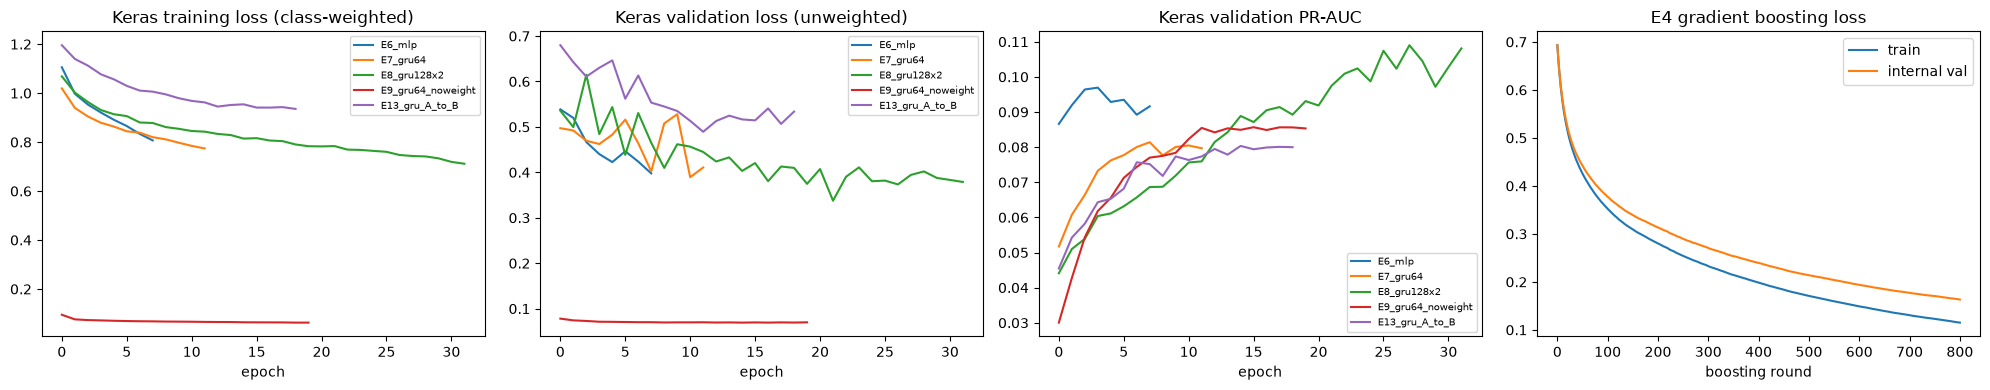

In [24]:
# Learning curves. Training loss is class-weighted (positive hours count ~55x), validation loss is not,
# so they are on different scales and get separate panels.
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for rid, h in HIST.items():
    axes[0].plot(h["loss"], label=rid)
    axes[1].plot(h["val_loss"], label=rid)
    axes[2].plot(h["val_auprc"], label=rid)
axes[0].set_title("Keras training loss (class-weighted)")
axes[1].set_title("Keras validation loss (unweighted)")
axes[2].set_title("Keras validation PR-AUC")
for a in axes[:3]:
    a.set_xlabel("epoch"); a.legend(fontsize=7)
h4 = MODELS["E4"].steps[-1][1]
axes[3].plot(-h4.train_score_, label="train"); axes[3].plot(-h4.validation_score_, label="internal val")
axes[3].set_title("E4 gradient boosting loss"); axes[3].set_xlabel("boosting round"); axes[3].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/learning_curves.png", dpi=150); plt.show()

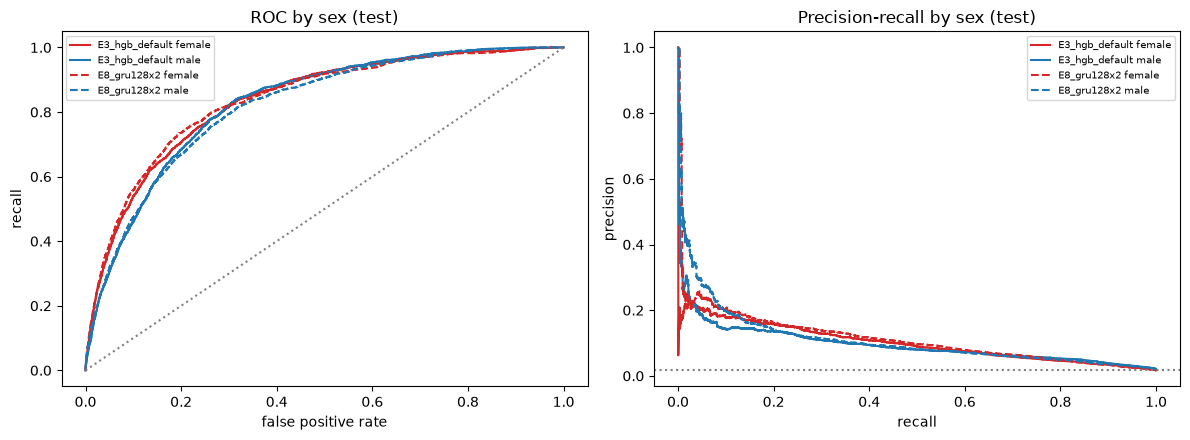

In [25]:
# ROC and precision-recall curves by sex for the best tree model and the best GRU
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gt = M["test"].Gender.values
for run, ls in [(best_ml, "-"), (best_gru_id, "--")]:
    st = SCORES[run][1]
    for g, col in [(0, "tab:red"), (1, "tab:blue")]:
        m_ = gt == g
        fpr, tpr, _ = roc_curve(y["test"][m_], st[m_]); axes[0].plot(fpr, tpr, ls, color=col, label=f"{run} {SEX_NAME[g]}")
        p, r, _ = precision_recall_curve(y["test"][m_], st[m_]); axes[1].plot(r, p, ls, color=col, label=f"{run} {SEX_NAME[g]}")
axes[0].plot([0, 1], [0, 1], ":", color="grey"); axes[0].set(title="ROC by sex (test)", xlabel="false positive rate", ylabel="recall")
axes[1].axhline(y["test"].mean(), ls=":", color="grey"); axes[1].set(title="Precision-recall by sex (test)", xlabel="recall", ylabel="precision")
for a in axes: a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/roc_pr_by_sex.png", dpi=150); plt.show()

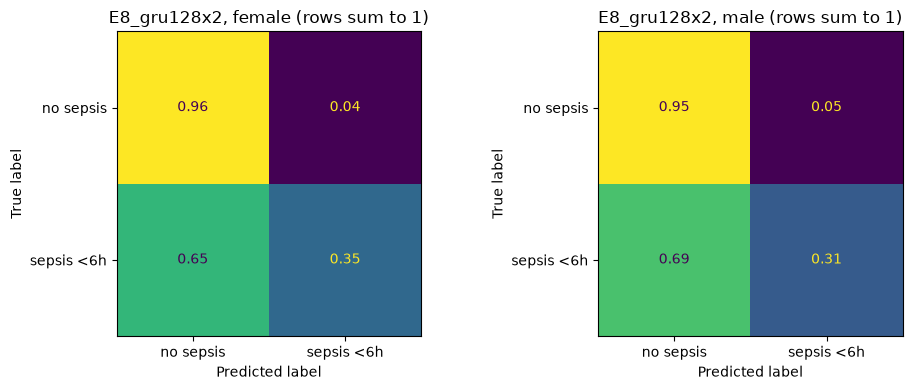

In [26]:
# Confusion matrices at the shared threshold, women vs men
sv, st = SCORES[best_run]
thr = threshold_for_fpr(y["val"], sv)    # alarm budget: 5% of non-sepsis hours
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, g in zip(axes, [0, 1]):
    m_ = gt == g
    cm = confusion_matrix(y["test"][m_], (st[m_] >= thr).astype(int), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=["no sepsis", "sepsis <6h"]).plot(ax=ax, colorbar=False, values_format=".2f")
    ax.set_title(f"{best_run}, {SEX_NAME[g]} (rows sum to 1)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_by_sex.png", dpi=150); plt.show()

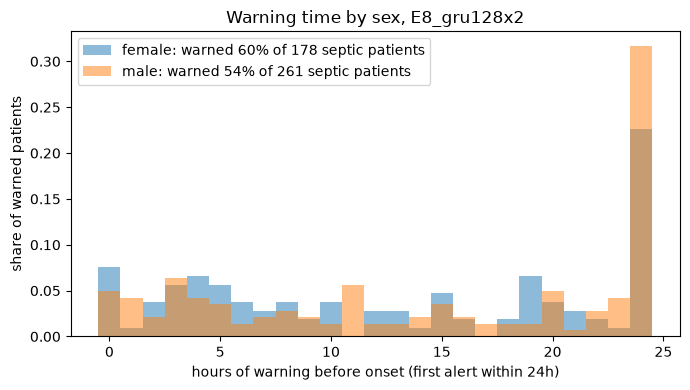

In [27]:
# Hours of warning before sepsis onset, women vs men (best model, alarm-budget threshold, 24h window)
on = onset_hour(M["test"])
lead = warning_lead(M["test"].assign(alert=st >= thr), on)
sex_of = M["test"].groupby("patient").Gender.first().reindex(on.index).map(SEX_NAME)
fig, ax = plt.subplots(figsize=(7, 4))
for s_ in ["female", "male"]:
    l_ = lead[sex_of == s_]
    ax.hist(l_.dropna(), bins=np.arange(0, WARN_WINDOW + 2) - 0.5, alpha=.5, density=True,
            label=f"{s_}: warned {l_.notna().mean():.0%} of {len(l_)} septic patients")
ax.set_xlabel(f"hours of warning before onset (first alert within {WARN_WINDOW}h)"); ax.set_ylabel("share of warned patients")
ax.set_title(f"Warning time by sex, {best_run}"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/lead_time_by_sex.png", dpi=150); plt.show()

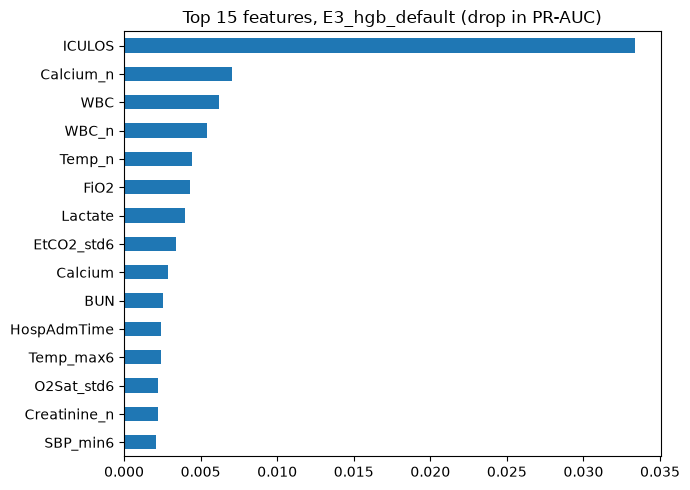

In [28]:
# Which features matter? Permutation importance of the best tree model on a sample of test rows
from sklearn.inspection import permutation_importance
best_model = MODELS[best_ml.split("_")[0]]
cols = best_model.used_cols
samp = np.random.default_rng(SEED).choice(len(y["test"]), min(60_000, len(y["test"])), replace=False)
pi = permutation_importance(best_model, X["test"][cols].iloc[samp], y["test"][samp], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
imp_s = pd.Series(pi.importances_mean, index=cols).sort_values().tail(15)
imp_s.plot.barh(figsize=(7, 5), title=f"Top 15 features, {best_ml} (drop in PR-AUC)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/feature_importance.png", dpi=150); plt.show()

## 12. Save the best models
These go in the Google Drive folder (the raw data is not committed to GitHub).

In [29]:
joblib.dump({"model": MODELS[best_ml.split("_")[0]], "features": MODELS[best_ml.split("_")[0]].used_cols},
            f"{MODEL_DIR}/best_ml_{best_ml}.joblib")
best_gru.save(f"{MODEL_DIR}/best_dl_{best_gru_id}.keras")
json.dump({"seq_mu": seq_mu.to_dict(), "seq_sd": seq_sd.to_dict(), "clin": CLIN},
          open(f"{MODEL_DIR}/gru_input_scaling.json", "w"))
print("saved:", os.listdir(MODEL_DIR))
print("Open TensorBoard with:  tensorboard --logdir logs")

saved: ['best_ml_E3_hgb_default.joblib', 'gru_input_scaling.json', 'best_dl_E8_gru128x2.keras', 'runs']
Open TensorBoard with:  tensorboard --logdir logs
